# Loading Dataset and CNN — Local JupyterLab
*Rolando A. Pula*

This notebook loads cat and dog images from `C:\Users\PC\Downloads\PetImages`, prepares them, trains a CNN, and compares it with a small Keras Tuner search.

Your folders should look like this:

```text
C:\Users\PC\Downloads\PetImages\
    Dog\
        0.jpg
    Cat\
        0.jpg
```

Open the notebook in JupyterLab and run its cells from top to bottom. The notebook can be saved in another folder; its dataset path is absolute.


## Setup

Run the next cell once in the notebook's Python kernel to install dependencies. Remove the leading `#` before `%pip`, run it, then restart the kernel if Jupyter asks. If TensorFlow cannot be installed in your current Python environment, use a compatible Python version in a new environment and select its kernel in JupyterLab.


In [1]:
# Uncomment and run once, then restart the kernel if requested:
# %pip install numpy matplotlib opencv-python tensorflow scikit-learn keras-tuner


## Checking and installing OpenCV

The original slides show installing OpenCV through **Anaconda Navigator** (Environments tab → search `opencv` → Install). If you're not using Anaconda, the `pip install opencv-python` command in the cell above does the same thing.

## Calling the Necessary Modules

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

## Data Preparation — your local folder

The dataset is set to `C:\Users\PC\Downloads\PetImages`. Inside it, keep the `Dog` and `Cat` folders. If you move the folder later, change `PET_IMAGES_PATH` in the next cell.


In [3]:
from pathlib import Path

# Folder containing the Dog and Cat subfolders on your Windows PC.
PET_IMAGES_PATH = Path(r"C:\Users\PC\Downloads\PetImages")
print("Jupyter working directory:", Path.cwd())
print("Looking for images at:", PET_IMAGES_PATH)


Jupyter working directory: C:\Users\PC\Downloads\PetImages
Looking for images at: C:\Users\PC\Downloads\PetImages


## Check the dataset folder

Extract the downloaded archive first if necessary. `PetImages` must directly contain `Dog` and `Cat`; there should be no extra nested `PetImages` folder. The next cell checks the location and stops with an actionable error if the layout is wrong.


In [4]:
dataset_dir = PET_IMAGES_PATH.expanduser()
if not dataset_dir.is_dir():
    raise FileNotFoundError(
        f"Missing dataset folder: {dataset_dir}\n"
        "Extract PetImages beside this notebook or update PET_IMAGES_PATH in the cell above."
    )
CATEGORIES = ["Dog", "Cat"]  # 0 = Dog, 1 = Cat
for category in CATEGORIES:
    category_dir = dataset_dir / category
    if not category_dir.is_dir():
        raise FileNotFoundError(
            f"Missing {category_dir}. PetImages must directly contain Dog and Cat folders."
        )
    print(f"{category}: {len(list(category_dir.glob('*.jpg')))} JPG files")
print("Dataset ready:", dataset_dir.resolve())


Dog: 12500 JPG files
Cat: 12500 JPG files
Dataset ready: C:\Users\PC\Downloads\PetImages


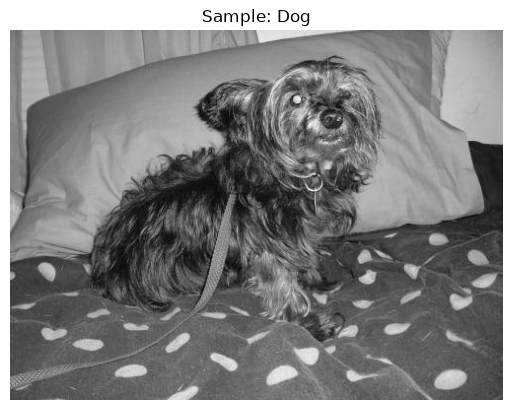

In [5]:
DATADIR = str(dataset_dir)
img_array = None
for category in CATEGORIES:
    for img in (dataset_dir / category).iterdir():
        if not img.is_file():
            continue
        candidate = cv2.imread(str(img), cv2.IMREAD_GRAYSCALE)
        if candidate is not None:
            img_array = candidate
            plt.imshow(img_array, cmap="gray")
            plt.title(f"Sample: {category}")
            plt.axis("off")
            plt.show()
            break
    if img_array is not None:
        break
if img_array is None:
    raise ValueError("No readable images found inside PetImages/Dog or PetImages/Cat.")


## Image Inspection

In [6]:
print(img_array)          # Displaying the image in array form (just for checking)
print(img_array.shape)    # checking the resolution of the image

[[117 117 119 ... 133 132 132]
 [118 117 119 ... 135 134 134]
 [119 118 120 ... 137 136 136]
 ...
 [ 79  74  73 ...  80  76  73]
 [ 78  72  69 ...  72  73  74]
 [ 74  71  70 ...  75  73  71]]
(375, 500)


## Image Resizing

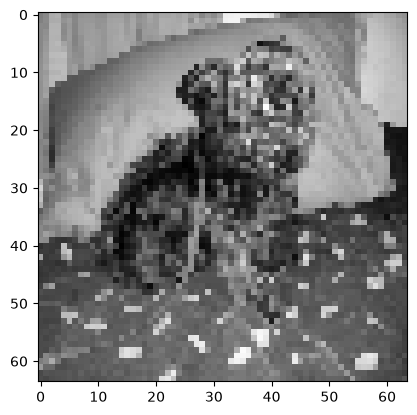

In [7]:
IMG_SIZE = 64  # Smaller images reduce both memory use and training time.
MAX_PER_CLASS = 2000  # Change to 1000 if your PC still runs out of memory.

new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
plt.imshow(new_array, cmap='gray')
plt.show()


## Assigning Training Data

In [8]:
training_data = []

def create_training_data():
    rng = np.random.default_rng(42)
    for class_num, category in enumerate(CATEGORIES):
        path = os.path.join(DATADIR, category)
        files = list(os.listdir(path))
        rng.shuffle(files)
        loaded = 0
        for img in files:
            if loaded >= MAX_PER_CLASS:
                break
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            if img_array is None:
                continue
            try:
                training_data.append([cv2.resize(img_array, (IMG_SIZE, IMG_SIZE)), class_num])
                loaded += 1
            except cv2.error:
                continue
        print(f"{category}: {loaded} images loaded")

create_training_data()


Dog: 2000 images loaded
Cat: 2000 images loaded


## Checking the Number of Training Data

In [9]:
print(len(training_data))

4000


## Randomizing/Shuffling the Data

In [10]:
import random
random.shuffle(training_data)

for sample in training_data[:10]:
    print(sample[1])

0
0
1
1
0
1
1
0
1
0


## Assigning Variables for Features and Labels

In [11]:
X = []  # feature set
y = []  # labels

for features, label in training_data:
    X.append(features)
    y.append(label)

X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)  # 1 is for grayscale
y = np.array(y)  # Keras expects the labels as an array too

## Using the Pickle Module

In [12]:
import pickle  # pickle lets you save your training data, avoiding recreating it
                # from scratch every time you want to adjust the model

with open('X.pickle', 'wb') as f:
    pickle.dump(X, f)

with open('y.pickle', 'wb') as g:
    pickle.dump(y, g)

## Using Pickle (Loading It Back)

In [13]:
pickle_in = open('X.pickle', 'rb')
X = pickle.load(pickle_in)

X[1]

array([[[164],
        [ 72],
        [ 76],
        ...,
        [183],
        [191],
        [181]],

       [[ 63],
        [ 80],
        [ 65],
        ...,
        [173],
        [171],
        [169]],

       [[ 39],
        [ 59],
        [ 76],
        ...,
        [164],
        [168],
        [166]],

       ...,

       [[ 89],
        [194],
        [ 99],
        ...,
        [176],
        [186],
        [185]],

       [[220],
        [203],
        [100],
        ...,
        [172],
        [175],
        [182]],

       [[210],
        [144],
        [110],
        ...,
        [173],
        [176],
        [175]]], shape=(64, 64, 1), dtype=uint8)

## What is a CNN?

**CNN** stands for **Convolutional Neural Network** — a type of neural network especially well suited to image data because it learns spatial patterns (edges, textures, shapes) through convolution and pooling layers instead of treating every pixel independently.

Further reading:
- https://medium.com/data-science-group-iitr/building-a-convolutional-neural-network-in-python-with-tensorflow-d251c3ca8117
- https://hackernoon.com/what-is-a-capsnet-or-capsule-network-2bfbe48769cc

## Using a CNN for Classification of Images

In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
import pickle

X = pickle.load(open('X.pickle', 'rb'))
y = pickle.load(open('y.pickle', 'rb'))

## Building, Compiling, and Training the CNN

`X = X/255.0` normalizes the pixel values (0-255) down to the 0-1 range, which helps the network train faster and more stably.

> Training for the full 200 epochs on the whole dataset can take a long time on CPU. Reduce `epochs` (e.g. to 10) for a quick test run, and increase it back up once you know the pipeline works.

In [15]:
# Keep one float32 copy instead of NumPy's float64 default.
X = X.astype(np.float32) / 255.0

model = Sequential()
model.add(Input(shape=X.shape[1:]))

model.add(Conv2D(2, (3, 3)))
#model.add(Conv2D(64, (3, 3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(64))
model.add(Dense(64))
model.add(Dense(1))
model.add(Activation('sigmoid'))

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=['accuracy'])



In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 2)           │              20 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 62, 62, 2)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 2)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 29, 29, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         147,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 1)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 189,909 (741.83 KB)

 Trainable params: 189,909 (741.83 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Use the same validation samples for manual and tuned model comparison.
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
history = model.fit(
    X_train, y_train, batch_size=32, epochs=3,
    validation_data=(X_val, y_val), verbose=1
)


Epoch 1/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.5241 - loss: 0.6953 - val_accuracy: 0.5375 - val_loss: 0.6867
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.5581 - loss: 0.6816 - val_accuracy: 0.5800 - val_loss: 0.6729
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.6109 - loss: 0.6562 - val_accuracy: 0.6150 - val_loss: 0.6568


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 2)           │              20 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 62, 62, 2)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 2)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 29, 29, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         147,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 1)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 569,729 (2.17 MB)

 Trainable params: 189,909 (741.83 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 379,820 (1.45 MB)

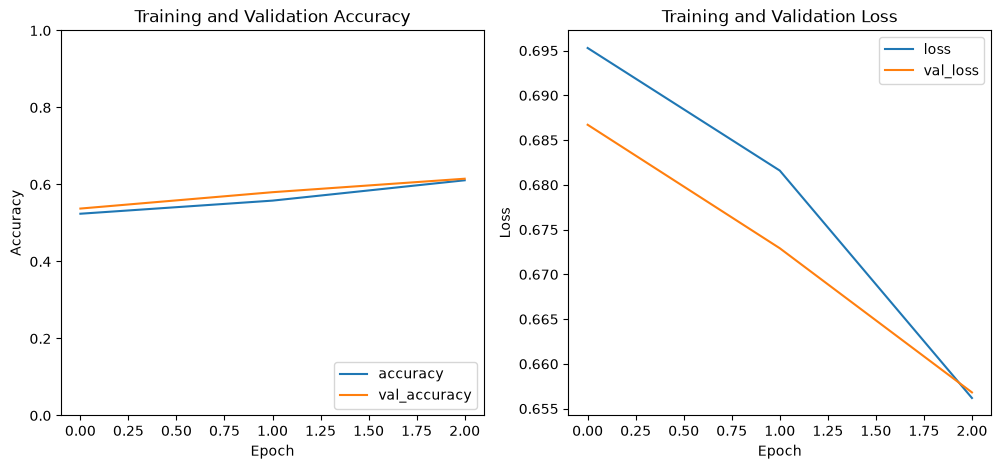

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step

Confusion Matrix:
[[288 112]
 [196 204]]


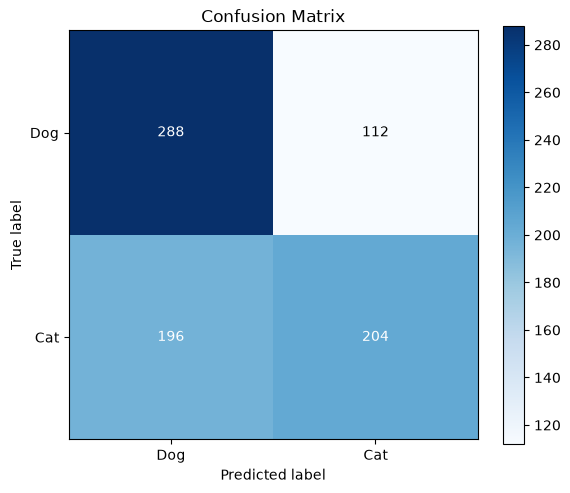

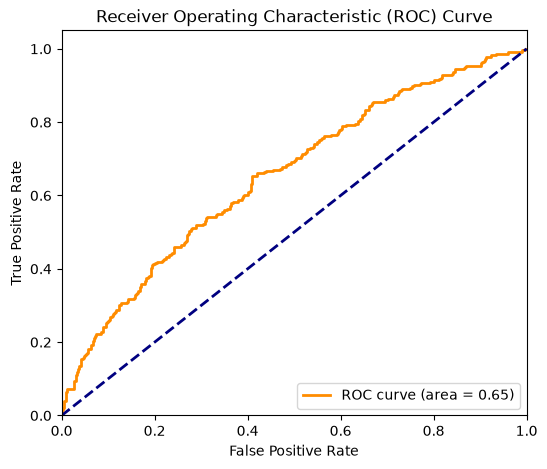

In [18]:
model.summary()

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc
import numpy as np # numpy is already imported as np earlier

# Plot training accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

# Get predictions for confusion matrix and ROC
y_pred_proba = model.predict(X_val, batch_size=32).ravel() # .ravel() to flatten to 1D array
y_pred = (y_pred_proba > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_val, y_pred)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(np.unique(y)))
CATEGORIES = ["Dog", "Cat"]
plt.xticks(tick_marks, CATEGORIES)
plt.yticks(tick_marks, CATEGORIES)
plt.ylabel('True label')
plt.xlabel('Predicted label')
fmt = 'd'
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, format(cm[i, j], fmt),
             ha="center", va="center",
             color="white" if cm[i, j] > thresh else "black")
plt.tight_layout()
plt.show()

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [19]:
import tensorflow as tf

# Define the filename for your model
model_filename = 'dog_cat_classifier.keras' # .keras is the recommended extension for Keras models

# Save the model
model.save(model_filename)
print(f"Model saved to {model_filename}")

# To load the model later (you can do this in a new session or script)
loaded_model = tf.keras.models.load_model(model_filename)
print(f"Model loaded from {model_filename}")

# You can then use the loaded_model for predictions or further evaluation
# For example, let's make predictions with the loaded model and compare
loaded_model_predictions = loaded_model.predict(X[:5])
print("\nExample predictions from loaded model:")
print(loaded_model_predictions[:5])


Model saved to dog_cat_classifier.keras
Model loaded from dog_cat_classifier.keras
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step

Example predictions from loaded model:
[[0.38294482]
 [0.49449268]
 [0.6754675 ]
 [0.42822295]
 [0.35358885]]


## Prediction Inference

Now that the model is loaded, we can use it to make predictions on new, unseen data. For demonstration purposes, I'll take a few samples from your existing `X` data to illustrate how to get predictions from the `loaded_model`.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
Predictions for the test samples:
Sample 1: Predicted Class = Dog (Confidence: 61.71%) 
Sample 2: Predicted Class = Dog (Confidence: 50.55%) 
Sample 3: Predicted Class = Cat (Confidence: 67.55%) 
Sample 4: Predicted Class = Dog (Confidence: 57.18%) 
Sample 5: Predicted Class = Dog (Confidence: 64.64%) 


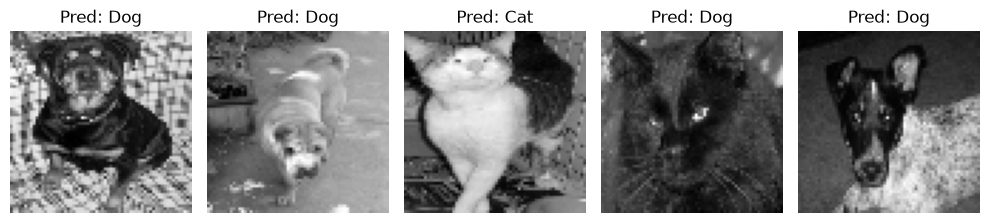

In [20]:
# Select a small subset of data for inference (e.g., the first 5 samples)
# In a real scenario, this would be entirely new, unseen test data.
test_samples = X[:5]

# Make predictions using the loaded model
inference_predictions = loaded_model.predict(test_samples)

print("Predictions for the test samples:")
for i, prediction in enumerate(inference_predictions):
    # Assuming binary classification with sigmoid output, values close to 1 are 'Cat', close to 0 are 'Dog'
    predicted_class = 'Cat' if prediction[0] > 0.5 else 'Dog'
    probability = (prediction[0] if predicted_class == "Cat" else 1 - prediction[0]) * 100
    print(f"Sample {i+1}: Predicted Class = {predicted_class} (Confidence: {probability:.2f}%) ")

# Optionally, display the images and their predictions
plt.figure(figsize=(10, 4))
for i in range(min(5, len(test_samples))):
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_samples[i].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    predicted_class = 'Cat' if inference_predictions[i][0] > 0.5 else 'Dog'
    plt.title(f"Pred: {predicted_class}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## Hyperparameter Optimization with Keras Tuner

The CNN above used one fixed, hand-picked set of hyperparameters (a very thin first conv layer with only 2 filters, no dropout, a single learning rate, and a batch size chosen without any experimentation). This section uses [Keras Tuner](https://keras.io/keras_tuner/) to search over several hyperparameters automatically and picks the configuration that gets the best validation accuracy, instead of guessing.

Hyperparameters tuned in this section:

- **Number of convolutional blocks** (2–4)
- **Filters per convolutional layer** (32–256, in steps of 32)
- **Kernel size per convolutional layer** (3×3 or 5×5)
- **Number of dense layers** (1–2) and their **width** (32–256 units)
- **Dropout rate** (0.0–0.5) — the original model had no dropout at all, which is a common cause of overfitting
- **Learning rate** (1e-4 to 1e-2, sampled on a log scale)
- **Optimizer** (Adam vs. RMSprop)
- **Batch size** (32, 64, or 128)

> **Compute note:** hyperparameter search trains many candidate models, so it takes noticeably longer than training a single model. On a local PC, a GPU is optional; CPU searches may take several minutes. If you just want to see the mechanism work, lower `max_epochs` in the tuner and `epochs` in `tuner.search(...)` first, then raise them once you know it runs end to end.

In [21]:
# Run this once if keras-tuner isn't already installed.
%pip install -q keras-tuner

Note: you may need to restart the kernel to use updated packages.


In [22]:
import keras_tuner as kt

# Reuse the baseline's validation split so the comparison uses identical samples.
print(f"Train: {len(X_train)} samples | Validation: {len(X_val)} samples")


Train: 3200 samples | Validation: 800 samples


In [23]:
def build_model(hp):
    """Builds a CNN whose architecture and optimizer are controlled by `hp`."""
    model = Sequential()
    model.add(Input(shape=X.shape[1:]))

    # Number of convolutional blocks: 2 to 4
    n_conv_layers = hp.Int("n_conv_layers", min_value=2, max_value=3, step=1)

    for i in range(n_conv_layers):
        filters = hp.Int(f"filters_{i}", min_value=16, max_value=64, step=16)
        kernel_size = hp.Choice(f"kernel_size_{i}", values=[3, 5])
        model.add(Conv2D(filters, (kernel_size, kernel_size), padding="same"))
        model.add(Activation("relu"))
        model.add(MaxPooling2D(pool_size=(2, 2)))

    model.add(Flatten())

    # Number of dense layers: 1 to 2, each with its own tunable width
    n_dense_layers = hp.Int("n_dense_layers", min_value=1, max_value=1, step=1)
    for j in range(n_dense_layers):
        dense_units = hp.Int(f"dense_units_{j}", min_value=16, max_value=64, step=16)
        model.add(Dense(dense_units))
        model.add(Activation("relu"))

    # Dropout to fight overfitting - the original model had none
    dropout_rate = hp.Float("dropout_rate", min_value=0.0, max_value=0.5, step=0.1)
    model.add(Dropout(dropout_rate))

    model.add(Dense(1))
    model.add(Activation("sigmoid"))

    learning_rate = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2, sampling="log")
    optimizer_choice = hp.Choice("optimizer", values=["adam", "rmsprop"])

    if optimizer_choice == "adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)

    model.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    return model


class CNNHyperModel(kt.HyperModel):
    """Wraps build_model so batch size can be tuned alongside architecture."""

    def build(self, hp):
        return build_model(hp)

    def fit(self, hp, model, *args, **kwargs):
        batch_size = hp.Choice("batch_size", values=[32])
        return model.fit(*args, batch_size=batch_size, **kwargs)

In [24]:
# Lightweight trial-based tuning for a PC with limited resources.
# RandomSearch runs only a fixed number of complete trials.
# No EarlyStopping is used.

tuner = kt.RandomSearch(
    CNNHyperModel(),
    objective="val_accuracy",
    max_trials=2,              # Increase later (e.g., 5 or 10) if your PC can handle it
    executions_per_trial=1,
    directory="kt_dir",
    project_name="dogs_vs_cats_tuning_trial_only",
    overwrite=True,
)

tuner.search_space_summary()

tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=3,                  # Each trial trains for 3 epochs
    verbose=1,
)


Trial 2 Complete [00h 01m 03s]
val_accuracy: 0.6537500023841858

Best val_accuracy So Far: 0.6537500023841858
Total elapsed time: 00h 01m 57s


In [25]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters found:")
for param, value in best_hp.values.items():
    print(f"  {param}: {value}")

Best hyperparameters found:
  n_conv_layers: 3
  filters_0: 32
  kernel_size_0: 5
  filters_1: 64
  kernel_size_1: 3
  n_dense_layers: 1
  dense_units_0: 64
  dropout_rate: 0.30000000000000004
  learning_rate: 0.0005522541253612088
  optimizer: adam
  filters_2: 32
  kernel_size_2: 3
  batch_size: 32


## Training the Tuned Model

The best hyperparameters from the fixed-number trial search are used to rebuild the CNN.

To keep the process predictable and lighter on the PC, The final model trains for at most 5 epochs and can stop earlier if validation loss stops improving. If the computer is still running out of memory or crashing, reduce the number of epochs, image size, batch size, or `max_trials`.


In [26]:
best_model = tuner.hypermodel.build(best_hp)
tuned_batch_size = best_hp.get("batch_size")

tuned_history = best_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=tuned_batch_size,
    epochs=5,                  # Upper bound; early stopping may finish sooner
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=1,
)


Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 147ms/step - accuracy: 0.5241 - loss: 0.6931 - val_accuracy: 0.5188 - val_loss: 0.6893
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 15s 148ms/step - accuracy: 0.5738 - loss: 0.6800 - val_accuracy: 0.6200 - val_loss: 0.6529
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 147ms/step - accuracy: 0.6309 - loss: 0.6420 - val_accuracy: 0.6288 - val_loss: 0.6509
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 139ms/step - accuracy: 0.6700 - loss: 0.6045 - val_accuracy: 0.6825 - val_loss: 0.6072
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 147ms/step - accuracy: 0.7013 - loss: 0.5786 - val_accuracy: 0.6562 - val_loss: 0.6348


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 64, 64, 32)          │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_5 (Activation)            │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_6 (Activation)            │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 16, 16, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_7 (Activation)            │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 8, 8, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │         131,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_8 (Activation)            │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_9 (Activation)            │ (None, 1)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 506,981 (1.93 MB)

 Trainable params: 168,993 (660.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 337,988 (1.29 MB)

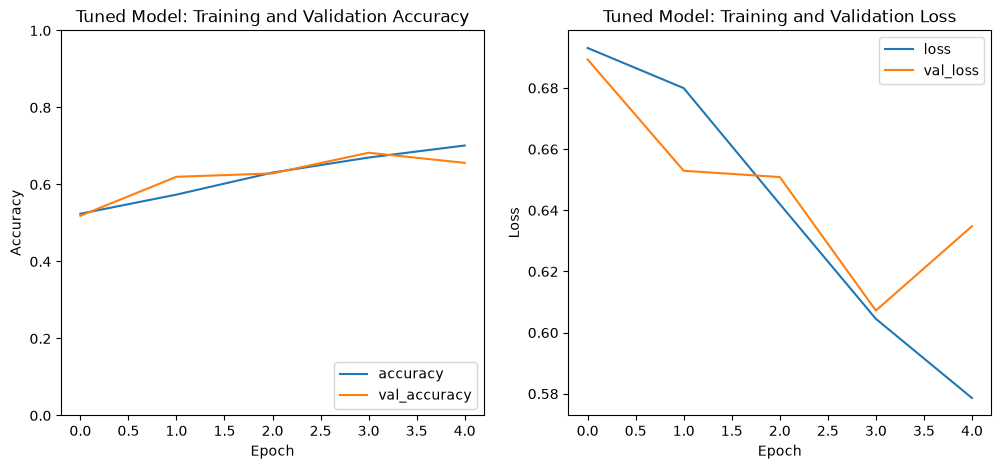

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step

Tuned Model Confusion Matrix (validation set):
[[289 111]
 [143 257]]


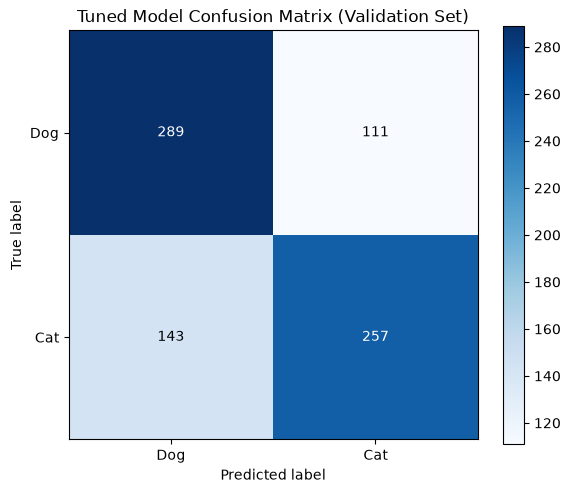

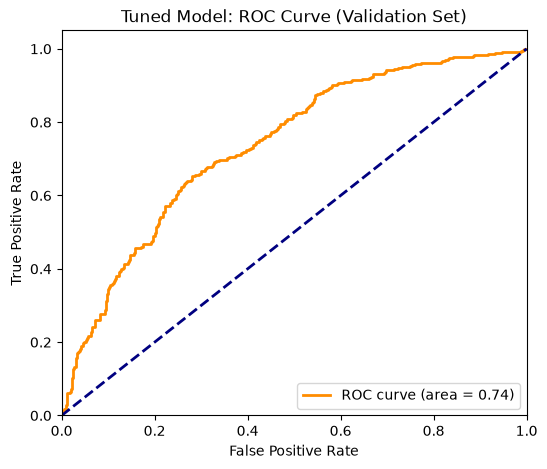

In [27]:
best_model.summary()

# Plot tuned model's training accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(tuned_history.history['accuracy'], label='accuracy')
plt.plot(tuned_history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title('Tuned Model: Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(tuned_history.history['loss'], label='loss')
plt.plot(tuned_history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Tuned Model: Training and Validation Loss')

plt.show()

# Evaluate on the held-out validation split (used for model selection and early stopping; use a separate test set for an unbiased final estimate)
val_pred_proba = best_model.predict(X_val).ravel()
val_pred = (val_pred_proba > 0.5).astype(int)

cm_tuned = confusion_matrix(y_val, val_pred)
print("\nTuned Model Confusion Matrix (validation set):")
print(cm_tuned)

plt.figure(figsize=(6, 5))
plt.imshow(cm_tuned, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Tuned Model Confusion Matrix (Validation Set)')
plt.colorbar()
tick_marks = np.arange(len(CATEGORIES))
plt.xticks(tick_marks, CATEGORIES)
plt.yticks(tick_marks, CATEGORIES)
plt.ylabel('True label')
plt.xlabel('Predicted label')
thresh = cm_tuned.max() / 2.
for i, j in np.ndindex(cm_tuned.shape):
    plt.text(j, i, format(cm_tuned[i, j], 'd'),
             ha="center", va="center",
             color="white" if cm_tuned[i, j] > thresh else "black")
plt.tight_layout()
plt.show()

fpr_tuned, tpr_tuned, _ = roc_curve(y_val, val_pred_proba)
roc_auc_tuned = auc(fpr_tuned, tpr_tuned)

plt.figure(figsize=(6, 5))
plt.plot(fpr_tuned, tpr_tuned, color='darkorange', lw=2,
         label=f'ROC curve (area = {roc_auc_tuned:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Tuned Model: ROC Curve (Validation Set)')
plt.legend(loc="lower right")
plt.show()

## Baseline vs. Tuned: Quick Comparison

For an apples-to-apples comparison, the cell below re-evaluates the **original, untuned model** from the previous section on the same validation split (`X_val`, `y_val`) that Keras Tuner searched against, then compares it with the tuned model above. Both models use the same training and validation split.

In [28]:
baseline_val_pred_proba = model.predict(X_val, batch_size=32).ravel()
baseline_val_pred = (baseline_val_pred_proba > 0.5).astype(int)
baseline_val_accuracy = (baseline_val_pred == y_val).mean()
baseline_fpr, baseline_tpr, _ = roc_curve(y_val, baseline_val_pred_proba)
baseline_auc = auc(baseline_fpr, baseline_tpr)

tuned_val_accuracy = (val_pred == y_val).mean()

print(f"{'Model':<22}{'Val. Accuracy':>15}{'Val. AUC':>12}")
print(f"{'Baseline (manual)':<22}{baseline_val_accuracy:>15.4f}{baseline_auc:>12.4f}")
print(f"{'Tuned (Keras Tuner)':<22}{tuned_val_accuracy:>15.4f}{roc_auc_tuned:>12.4f}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
Model                   Val. Accuracy    Val. AUC
Baseline (manual)              0.6150      0.6542
Tuned (Keras Tuner)            0.6825      0.7373


In [29]:
tuned_model_filename = 'dog_cat_classifier_tuned.keras'
best_model.save(tuned_model_filename)
print(f"Tuned model saved to {tuned_model_filename}")

Tuned model saved to dog_cat_classifier_tuned.keras
